# Lattice protein folding with QAOA

## The problem

A protein is a chain of amino acids that folds into a compact 3D shape that defines
its biological function. Predicting the lowest-energy fold is hard because the
number of possible folds grows exponentially with the chain length. We study the
simplest useful model, the **HP lattice model**:

- Each bead is **H** (hydrophobic) or **P** (polar).
- The chain sits on a square grid, one bead per site, and neighboring beads in
  the chain sit on neighboring sites. The chain cannot cross itself.
- Every pair of H beads that touch on the grid *without* being neighbors in the
  chain lowers the energy by 1. Hydrophobic beads like to cluster, so good folds
  bury the H beads together.

We want the fold with the lowest energy. That is an optimization problem, so we
write it as a **Hamiltonian** whose ground state is the best fold and search for
that ground state with **QAOA**, a variational algorithm.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Encoding | Write a fold as a bitstring; build the ansatz | `encoding.py` |
| 2. Operator | Turn the energy into a Hamiltonian | `ops.py` |
| 3. Execution | Run the loop on a simulator or hardware | `execution.py` |
| 4. Analysis | Decode, rank the folds, and plot | `analysis.py` |

The same steps are available as one command,
`python folding/main.py "HPPHHP" --encoding=binary`. This notebook walks through
them one at a time. The code lives in `../scripts/folding/` and is imported
here, so the notebook and the command line cannot drift apart. The encodings
follow Linn et al. (2024); see `lattice-folding-encodings.md` for the full
notes.

## Setup

By default this notebook runs on the noiseless Aer simulator. To run on IBM
hardware, set `backend_name` to a backend you can access (your saved Qiskit
account is used). Hardware jobs may wait in a queue.

- `sequence`: the chain of H and P beads.
- `encoding`: how a fold becomes bits: `"unary"`, `"binary"`, or `"bu"`
  (block-unary). Step 1 explains the trade-offs. Unary needs more qubits than
  the simulator handles comfortably for long chains.
- `grid`: the grid size. `auto_grid` picks the smallest near-square grid that
  fits the chain.
- `reps`: the number of QAOA layers. `starts`: how many random starting points
  the optimizer tries. `shots`: samples per measurement.

In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

# The folding code lives in ../scripts/folding.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/folding").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

sequence = "HPPHHP"
encoding = "binary"  # "unary", "binary", or "bu"
backend_name = None  # None = Aer simulator; or e.g. "ibm_rensselaer"
reps = 2
starts = 3
shots = 4096

grid = ops.auto_grid(len(sequence))
print(f"{sequence}: {len(sequence)} beads on a {grid[0]}x{grid[1]} grid")

HPPHHP: 6 beads on a 2x3 grid


## Step 1: Encoding a fold as a bitstring

**Coordinate model.** Each bead's choice is *which grid site it sits on*. Sites
are colored like a checkerboard (even or odd coordinate sum). Neighboring beads
must sit on opposite colors, so bead $i$ can only use sites of its own color:
that halves the number of choices per bead. The list of choice counts $(c_1,
\ldots, c_N)$ is the **cardinality vector**.

**Integer to bits.** Each bead's choice $r \in \{0, \ldots, c-1\}$ is written in
a bit code, and the codes of all beads are concatenated. One bit is one qubit.
Three codes:

- **Unary (one-hot):** $c$ bits, with bit $r$ set. It needs the most qubits, but
  every cost term involves at most two of them (2-local).
- **Binary:** $\lceil\log_2 c\rceil$ bits holding $r$ in base 2. Fewest qubits,
  but a term can couple all the bits of two beads, so the Hamiltonian is higher
  order.
- **Block-unary binary (BU):** groups of $g=3$ options share a block of 2 bits;
  exactly one block is nonzero. A middle ground whose locality is set by $g$,
  not by the grid size.

The table shows all three for $c=5$. Some bit patterns encode no choice at all
(for example `101` in binary when $c=5$). Those are **invalid** and must be
discouraged by the Hamiltonian.

In [2]:
print(f"{'r':>2}  {'unary':<7} {'binary':<7} {'bu (g=3)':<9}")
for r in range(5):
    unary, binary, bu = (enc.encode(r, 5, e) for e in enc.ENCODINGS)
    print(f"{r:>2}  {unary:<7} {binary:<7} {bu:<9}")

print()
cards = enc.coordinate_cardinality(len(sequence), grid)
print(f"Cardinality vector for {sequence} on {grid[0]}x{grid[1]}: {cards}")
for e in enc.ENCODINGS:
    print(f"  {e:<7} needs {enc.n_qubits(cards, e):>2} qubits")

 r  unary   binary  bu (g=3) 
 0  10000   000     0001     
 1  01000   001     0010     
 2  00100   010     0011     
 3  00010   011     0100     
 4  00001   100     1000     

Cardinality vector for HPPHHP on 2x3: [3, 3, 3, 3, 3, 3]
  unary   needs 18 qubits
  binary  needs 12 qubits
  bu      needs 12 qubits


### Decoding a bitstring

Going back is a lookup: split the bitstring into one block per bead, decode each
block to a site, and read off the coordinates. A block that is not a valid code
makes the whole bitstring invalid. To try it, we find the lowest-energy fold by
brute-force enumeration, encode it into bits, decode it again, and draw it on
its grid.

16 self-avoiding placements exist on this grid.
(Rotated and mirrored copies are counted separately.)
The encoding puts bead 0 on an even site, so it can reach only
the placements that start there.

Best fold [(0, 0), (1, 0), (1, 1), (0, 1), (0, 2), (1, 2)]
encodes to 000110000110 (binary)
Decodes back to: [(0, 0), (1, 0), (1, 1), (0, 1), (0, 2), (1, 2)]
A corrupted string decodes to: None


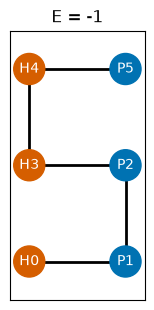

In [3]:
# Find the lowest-energy fold by brute force, then encode it into bits.
folds = list(ops.enumerate_folds(sequence, grid))
best = min(folds, key=lambda c: ops.fold_energy(c, sequence))
sites = enc.coordinate_sites(grid)  # [even sites, odd sites]
bits = ""
for i, (xy, c) in enumerate(zip(best, cards)):
    r = sites[i % 2].index(xy)  # which site of its color the bead is on
    bits += enc.encode(r, c, encoding)

print(f"{len(folds)} self-avoiding placements exist on this grid.")
print("(Rotated and mirrored copies are counted separately.)")
print("The encoding puts bead 0 on an even site, so it can reach only")
print("the placements that start there.")
print(f"\nBest fold {best}")
print(f"encodes to {bits} ({encoding})")
decoded = enc.decode_coordinate(bits, len(sequence), grid, encoding)
print("Decodes back to:", decoded)
broken = enc.decode_coordinate("1" * len(bits), len(sequence), grid, encoding)
print("A corrupted string decodes to:", broken)

fig, ax = plt.subplots(figsize=(3.5, 3.5))
energy = ops.fold_energy(best, sequence) + 0  # + 0 turns -0.0 into 0.0
analysis.draw_fold(ax, best, sequence, grid, f"E = {energy:+.0f}")
plt.show()

### The ansatz

**QAOA** (Quantum Approximate Optimization Algorithm) builds the trial state in
layers. Start in $|+\rangle^{\otimes n}$, an equal superposition of *every*
bitstring, then repeat $p$ times:

$$
|\psi(\boldsymbol\beta,\boldsymbol\gamma)\rangle = \prod_{k=1}^{p} e^{-i\beta_k
H_M}\, e^{-i\gamma_k H_C}\,|+\rangle^{\otimes n}.
$$

- $e^{-i\gamma H_C}$ is the **cost layer**. It gives each bitstring a phase
  proportional to its energy.
- $e^{-i\beta H_M}$ is the **mixer** ($H_M=\sum X_i$). It moves amplitude
  between bitstrings so the phases turn into probabilities.

The $2p$ angles are what the classical optimizer tunes. For unary encoding the
code swaps in an **XY mixer** started from a one-hot state, which never leaves
the "one site per bead" subspace.

The cost operator $H_C$ is built in Step 2. To see the structure now, we build
the ansatz around a placeholder operator.

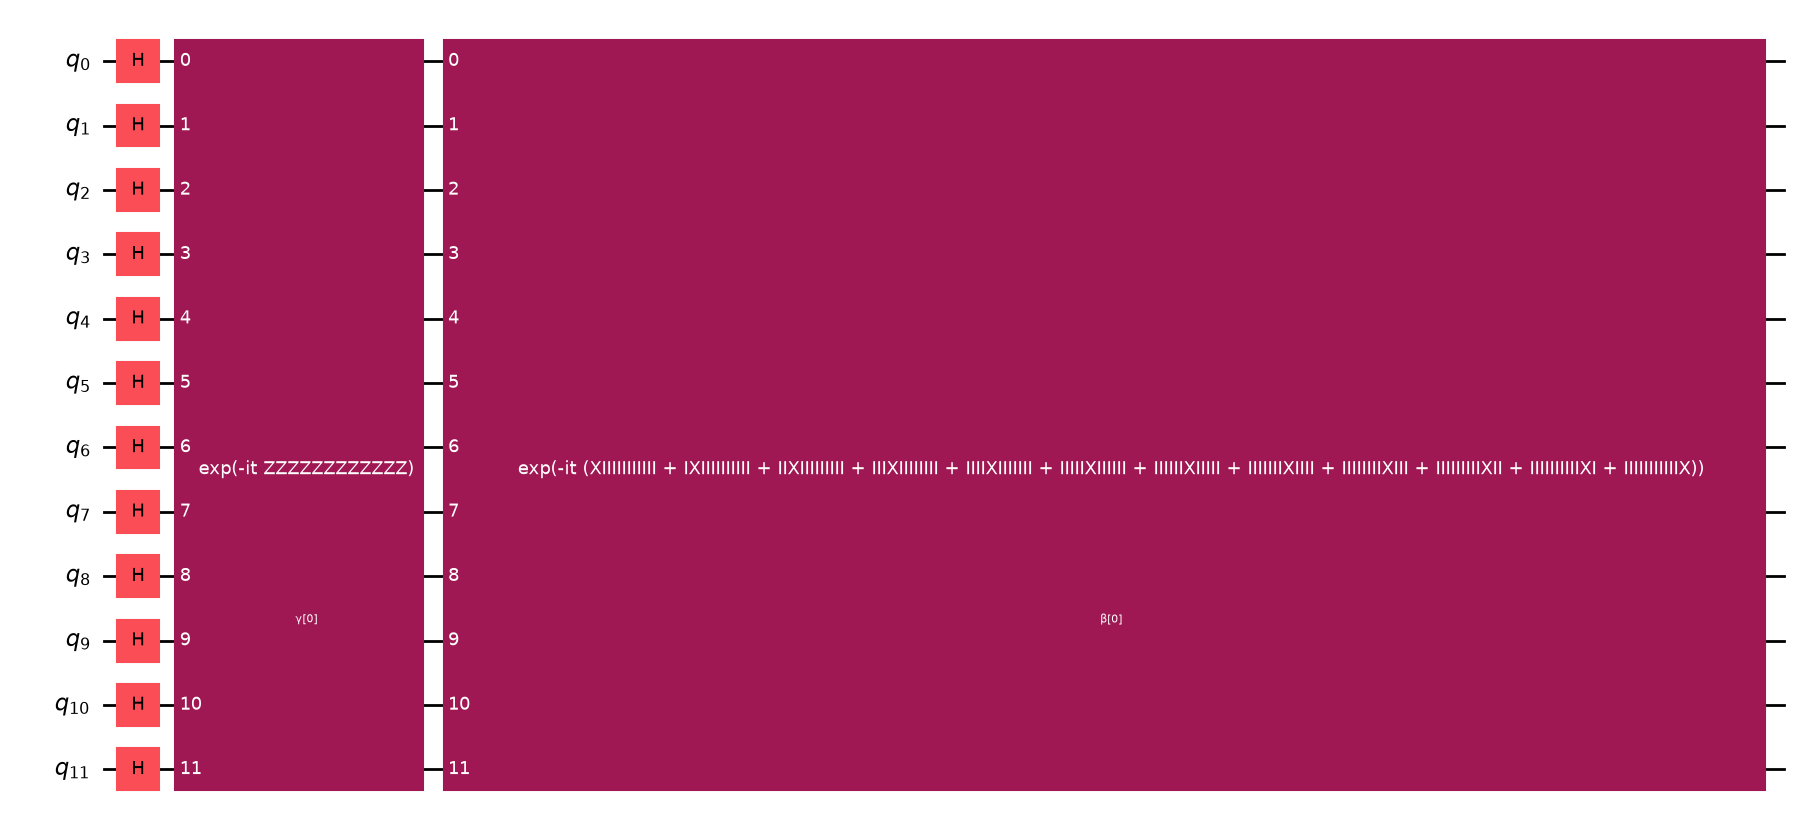

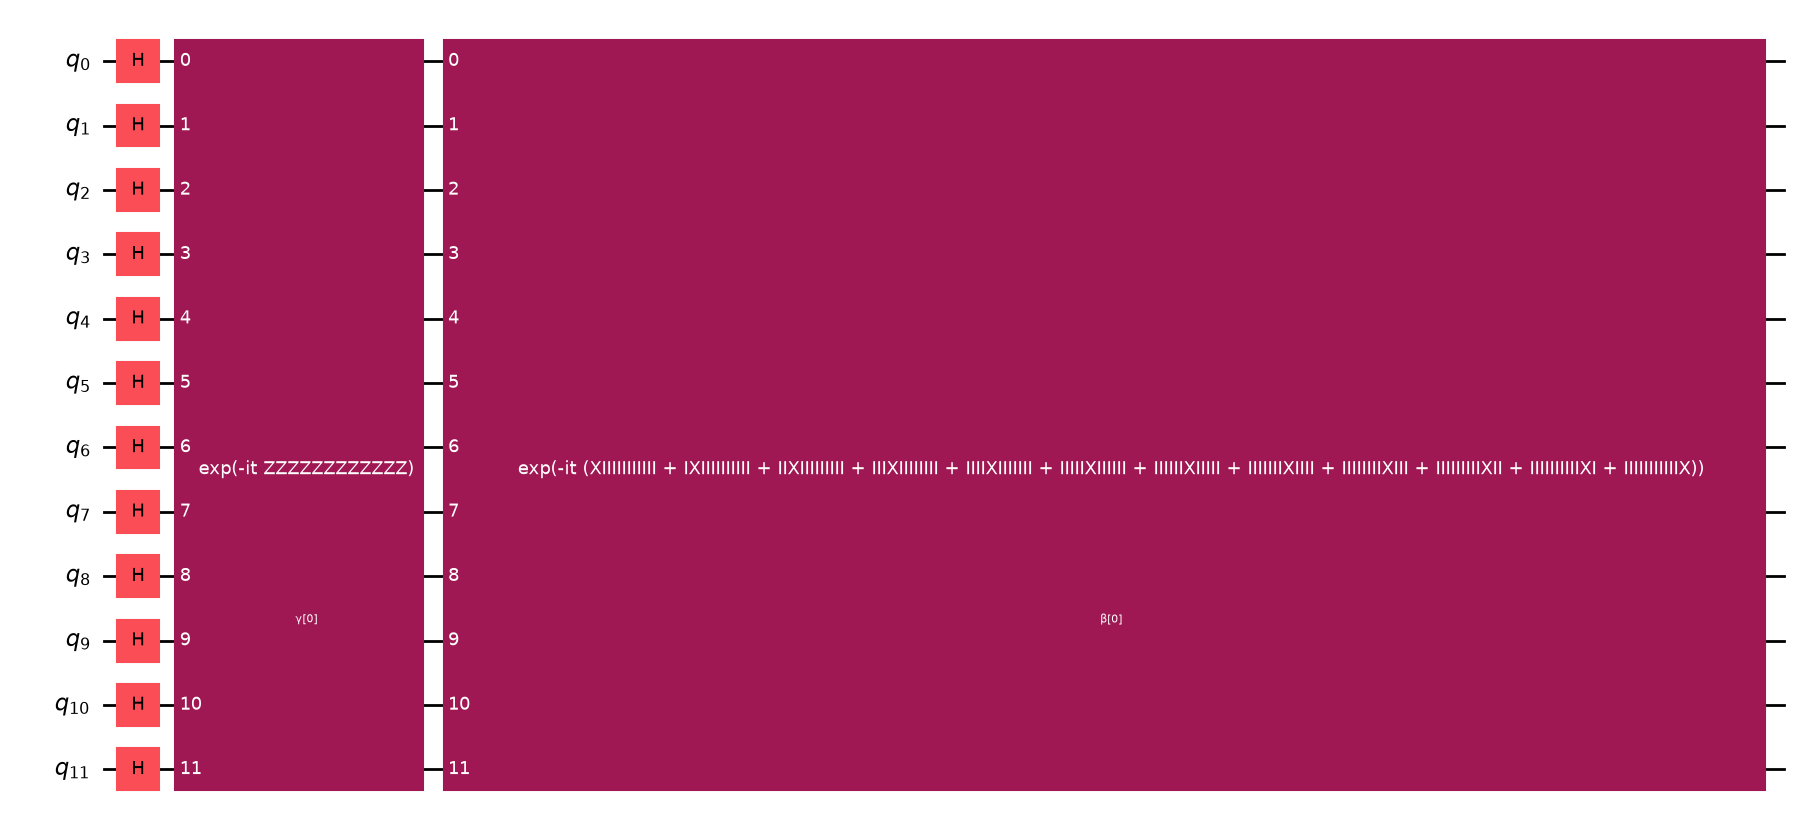

In [4]:
from qiskit.quantum_info import SparsePauliOp

n = enc.n_qubits(cards, encoding)
placeholder = SparsePauliOp("Z" * n)  # stand-in for the real cost operator
enc.build_ansatz(placeholder, cards, encoding, reps=1).decompose().draw(
    "mpl", fold=-1
)

## Stop and think: what did the encoding decide?

Before moving on, make sure these ideas are clear.

1. **A fold is a path through choices.** We never store coordinates on the
   quantum computer. We store, for each bead, *which site it sits on*, as bits.
   Classical code turns the measured bits back into a picture.
2. **Most bitstrings are not folds.** $n$ qubits give $2^n$ bitstrings, but only
   a handful are valid folds (Step 2 counts them). The rest either contain an
   invalid bead code or break a rule (two beads on one site, or neighbors that
   are not adjacent). The Hamiltonian has to make all of those expensive.
3. **The encoding is a trade.** Unary uses the most qubits but only two-body
   terms. Binary uses the fewest qubits but multi-qubit terms, which compile to
   long chains of two-qubit gates. Which is better depends on the hardware:
   trapped ions with native multi-qubit gates favor dense codes, while
   superconducting chips with only two-qubit gates favor sparse ones.
4. **The ansatz is fixed by the problem size.** Its only freedom is $2p$ angles.
   More layers can express more, but cost more gates and a harder optimization.

*Try it:* change `encoding` in Setup to `"bu"` and rerun. The qubit count should
stay the same for this chain. Why? (Hint: with $c=3$ options, $g=3$ gives one
block of 2 bits, the same as binary.)

## Step 2: The operator (the Hamiltonian)

We need a function of the bits whose minimum is the best fold. Let $y_{i,r}=1$
when bead $i$ takes choice $r$ (sits on the $r$-th site of its color). In unary,
$y_{i,r}$ is a single bit. In binary and BU, $y_{i,r}$ is a product of bits (or
their complements) that equals 1 only when the whole block spells the code for
$r$. The cost is a sum of four kinds of term:

- **Contact reward**, $-\varepsilon\, y_{i,r}\,y_{j,q}$: H beads $i$ and $j$
  with $j-i$ odd and at least 3, on adjacent sites $r$ and $q$.
- **No overlap**, $+\lambda\, y_{i,r}\,y_{j,r}$: two beads of the same color on
  the same site.
- **Connectivity**, $+\lambda\, y_{i,r}\,y_{i+1,q}$: consecutive beads on sites
  that are *not* adjacent.
- **Valid code**, $+\lambda\cdot$(invalid patterns): a bead's block of bits is
  not a legal code.

The penalty weight $\lambda$ is larger than any contact reward, so breaking a
rule never pays. Finally we substitute $x=(1-Z)/2$ for every bit, which turns
the polynomial into a sum of Pauli-$Z$ strings, an **Ising Hamiltonian** $H_C$
that is diagonal in the computational basis: the energy of a bitstring is the
eigenvalue of $H_C$ on it.

In [5]:
hamiltonian, cards, poly = ops.build_hamiltonian(encoding, sequence, grid)
labels = hamiltonian.paulis.to_labels()
weights = [sum(ch != "I" for ch in label) for label in labels]

print(f"{hamiltonian.num_qubits} qubits, {len(hamiltonian)} Pauli terms")
print("Terms by number of qubits acted on (locality):")
for w in sorted(set(weights)):
    print(f"  {w}-body: {weights.count(w)}")
print(f"Penalty weight {ops.LAM}, contact reward {ops.EPS}")

12 qubits, 106 Pauli terms
Terms by number of qubits acted on (locality):
  0-body: 1
  1-body: 12
  2-body: 43
  3-body: 43
  4-body: 7
Penalty weight 3.0, contact reward 1.0


### Does the Hamiltonian have the right ground state?

With 12 qubits we can check by brute force, which is exactly what the quantum
computer is supposed to do *without* enumerating. Because $H_C$ is diagonal we
can read every energy off its diagonal. The lowest energies should be valid
folds with the energies from the HP rule, and every invalid bitstring should sit
above them.

Six lowest-energy bitstrings:
 energy  bitstring     valid fold?
  -1.00  011010000001  True
  -1.00  101001000001  True
  -1.00  100100000110  True
  -1.00  000110000110  True
  +0.00  011010010000  True
  +0.00  000110100100  True

8 valid folds: energies -1 to +0
4088 invalid bitstrings: lowest energy +2.00


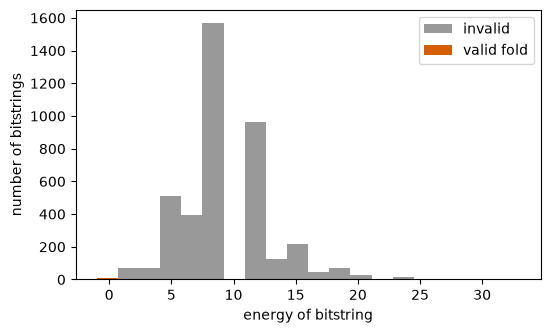

In [6]:
n = hamiltonian.num_qubits


def bits_of(i):
    # Basis state i as a bitstring in qubit order (qubit 0 first).
    return "".join(str((i >> k) & 1) for k in range(n))


if n <= 16:
    # H is diagonal, so its diagonal entries are the energies of the
    # bitstrings 0, 1, 2, ...
    diag = hamiltonian.to_matrix(sparse=True).diagonal().real
    folds = [
        enc.decode_coordinate(bits_of(i), len(sequence), grid, encoding)
        for i in range(2**n)
    ]
    is_valid = np.array([ops.is_valid_fold(c) for c in folds])

    print("Six lowest-energy bitstrings:")
    print(f"{'energy':>7}  {'bitstring':<{n}}  valid fold?")
    for i in np.argsort(diag)[:6]:
        print(f"{diag[i] + 0:>+7.2f}  {bits_of(i)}  {is_valid[i]}")

    low, high = diag[is_valid].min() + 0, diag[is_valid].max() + 0
    print(f"\n{is_valid.sum()} valid folds: energies {low:+.0f} to {high:+.0f}")
    print(
        f"{(~is_valid).sum()} invalid bitstrings: lowest energy "
        f"{diag[~is_valid].min():+.2f}"
    )

    plt.figure(figsize=(6, 3.5))
    plt.hist(
        [diag[~is_valid], diag[is_valid]],
        bins=20,
        stacked=True,
        color=["#999999", "#D55E00"],
        label=["invalid", "valid fold"],
    )
    plt.xlabel("energy of bitstring")
    plt.ylabel("number of bitstrings")
    plt.legend()
    plt.show()
else:
    print("Too many qubits to diagonalize classically; skipping the check.")

## Stop and think: what is the Hamiltonian doing?

1. **Energy equals the eigenvalue.** $H_C$ is diagonal, so $\langle
   x|H_C|x\rangle$ is the energy of bitstring $x$. A valid fold pays no penalty,
   so its energy is just the HP energy ($-\varepsilon$ per contact). An invalid
   string pays at least one penalty $\lambda$, which is why the histogram
   separates them.
2. **The ground state is the answer.** The lowest eigenvalue is the best fold.
   Verifying this by brute force is only possible because the problem is tiny:
   $2^{12}=4096$ strings here. For a 30-bead chain the same check would need
   more bitstrings than we could ever list. QAOA is meant to avoid that
   enumeration.
3. **Penalties are a design choice.** We pick $\lambda$ by hand. Too small and
   an invalid string with a good "energy" wins. Too large and the contact reward
   becomes a tiny ripple on a huge landscape, which is hard for the optimizer.
   This is the main practical difficulty with penalty methods.
4. **Locality shows up here.** The table of Pauli weights above is the hardware
   cost. A $k$-body term needs about $2(k-1)$ two-qubit gates in the cost layer,
   so higher-order terms in the binary encoding mean deeper circuits.

*Try it:* change `encoding` to `"unary"` (18 qubits, so skip the brute-force
cell) and compare the locality table. Which encoding has the larger maximum term
weight? Which has more terms?

## Step 3: Execution

Now the variational loop. Each iteration:

1. The classical optimizer (**COBYLA**, a gradient-free method that tolerates
   noisy energies) proposes the angles $(\boldsymbol\beta,\boldsymbol\gamma)$.
2. The quantum computer prepares
   $|\psi(\boldsymbol\beta,\boldsymbol\gamma)\rangle$ and the **Estimator**
   returns $\langle H_C\rangle$ from repeated shots.
3. The optimizer lowers $\langle H_C\rangle$ and repeats.

When the loop stops, we fix the best angles, add measurements, and **sample**
the circuit. Those samples (counts of each bitstring) are the result.

Two practical details:

- **Transpiling.** Hardware runs only a native gate set on specific physical
  qubits. We transpile once, and map the Hamiltonian onto the same layout
  (`apply_layout`) so the Estimator measures the right qubits. The angles stay
  symbolic, so one transpile serves every iteration.
- **Restarts.** QAOA landscapes have many local minima, so we run the loop from
  `starts` random points and sample the best. On hardware, all iterations run
  inside one **Session**: each iteration depends on the last, so keeping the
  queue slot avoids waiting in line every step.

`run` does all of this and returns the counts and the energy history. It takes a
minute or less on the simulator.

In [7]:
data = execution.run(
    sequence,
    grid,
    encoding,
    backend_name,
    reps=reps,
    starts=starts,
    shots=shots,
)
n_evals = sum(len(h) for h in data["history"])
print(f"\nTotal time: {data['seconds']:.1f} s; {n_evals} energy evaluations")

binary: 12 qubits, depth 380, 514 two-qubit gates on aer_simulator


  start 0: best <H> = +8.164 (38 evaluations)


  start 1: best <H> = +6.313 (54 evaluations)


  start 2: best <H> = +8.154 (45 evaluations)

Total time: 15.8 s; 137 energy evaluations


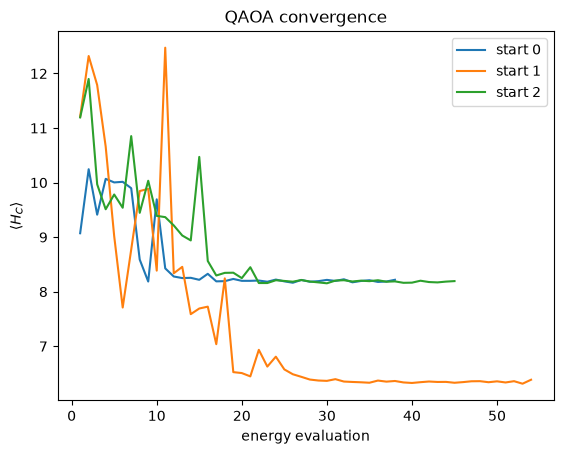

In [8]:
for k, hist in enumerate(data["history"]):
    plt.plot(range(1, len(hist) + 1), hist, label=f"start {k}")
plt.xlabel("energy evaluation")
plt.ylabel(r"$\langle H_C\rangle$")
plt.title("QAOA convergence")
plt.legend()
plt.show()

## Stop and think: what did the loop produce?

1. **The energy $\langle H_C\rangle$ is an average over bitstrings.** It is
   *not* the energy of one fold. A low average means probability piled onto
   low-energy strings, but a lot of it can still sit on invalid ones, which
   carry large penalties. That is why the curve levels off well above the best
   fold's energy.
2. **The final answer is a distribution.** We sample the optimized circuit and
   look at *which bitstrings appear*. The best fold is the lowest-energy valid
   string that shows up, not the minimum of the curve.
3. **Different starts land in different places.** Compare the curves: each start
   ends at a different value, so local minima are real. Hence the restarts.
4. **Why the odds are modest.** Of the $2^{12}$ bitstrings only 8 are valid
   folds, about 0.2% of the space. Two layers of QAOA concentrate some
   probability on them, but not much. More layers, more restarts, and a good
   penalty weight help, at the price of a deeper circuit and a harder
   optimization. On hardware, noise adds to the pressure: the deeper the
   circuit, the more the result washes out.

*Try it:* raise `reps` to 3 or `starts` to 6 and rerun this section. Does the
fraction of valid samples (printed in Step 4) change?

## Step 4: Analysis

We now do what the quantum computer cannot: look at the samples. For every
distinct bitstring we decode the fold, check that it is valid (every bead
placed, no shared site, neighbors adjacent), compute its HP energy, and sort. We
then draw

- the best conformation found, on its grid (H beads orange, P beads blue), and
- the **energy spectrum**: for each possible energy level, the probability the
  circuit sampled it, with the number of reachable folds at that level (from
  exact enumeration), plus the probability of an invalid sample.

Rotated and mirrored copies of a fold are different bitstrings, so they appear
as separate rows in the ranking.


HPPHHP on a 2x3 grid, binary encoding, aer_simulator, 4096 shots
Invalid samples: 98.1%
Distinct valid conformations sampled: 7

rank  energy     prob  bits          path
   1      -1    0.49%  000110000110  (0,0) (1,0) (1,1) (0,1) (0,2) (1,2)
   2      -1    0.39%  100100000110  (1,1) (1,0) (0,0) (0,1) (0,2) (1,2)
   3      -1    0.34%  101001000001  (1,1) (1,2) (0,2) (0,1) (0,0) (1,0)
   4      -1    0.29%  011010000001  (0,2) (1,2) (1,1) (0,1) (0,0) (1,0)
   5      +0    0.22%  010000011010  (0,2) (0,1) (0,0) (1,0) (1,1) (1,2)
   6      +0    0.12%  011010010000  (0,2) (1,2) (1,1) (1,0) (0,0) (0,1)
   7      +0    0.02%  000001101001  (0,0) (0,1) (0,2) (1,2) (1,1) (1,0)

Saved /tmp/folding_result.png


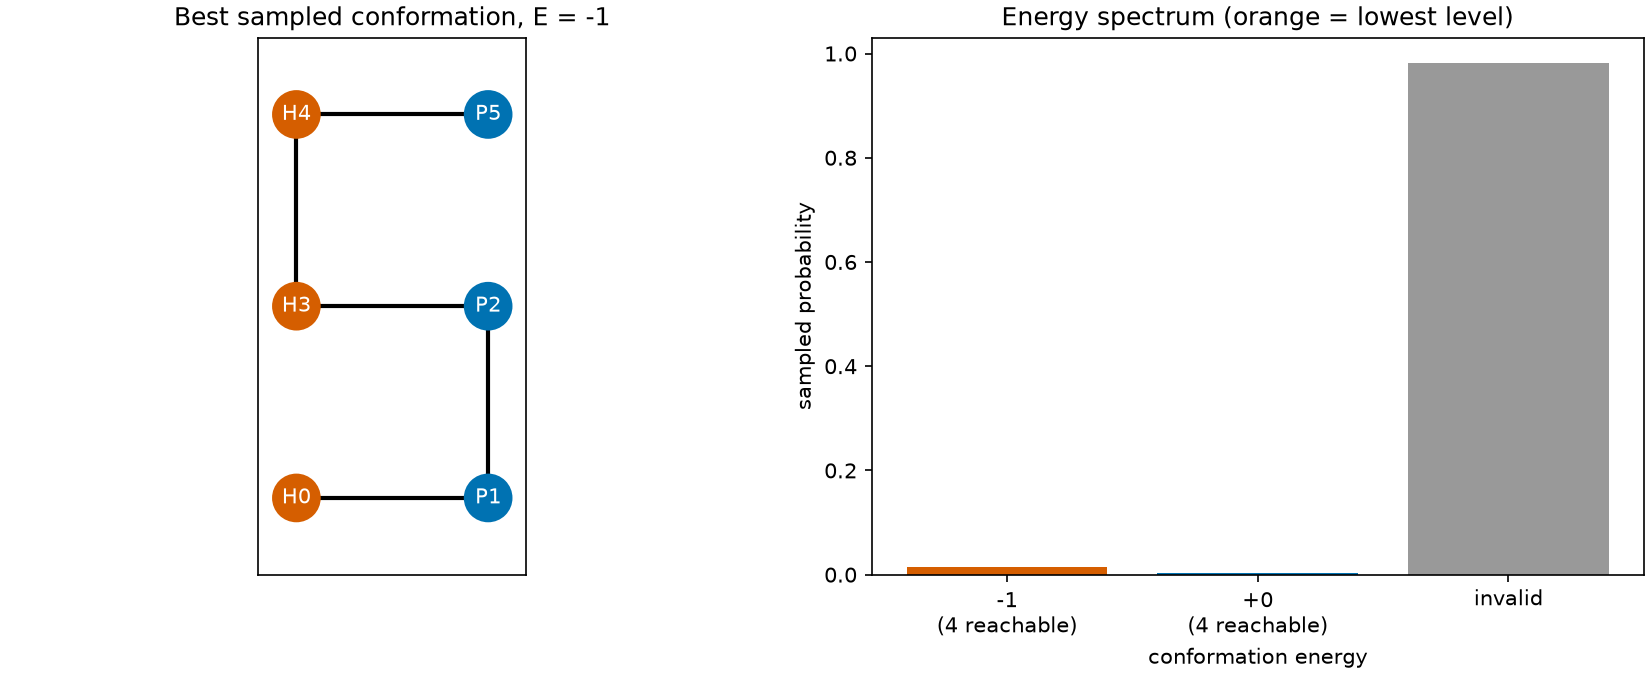

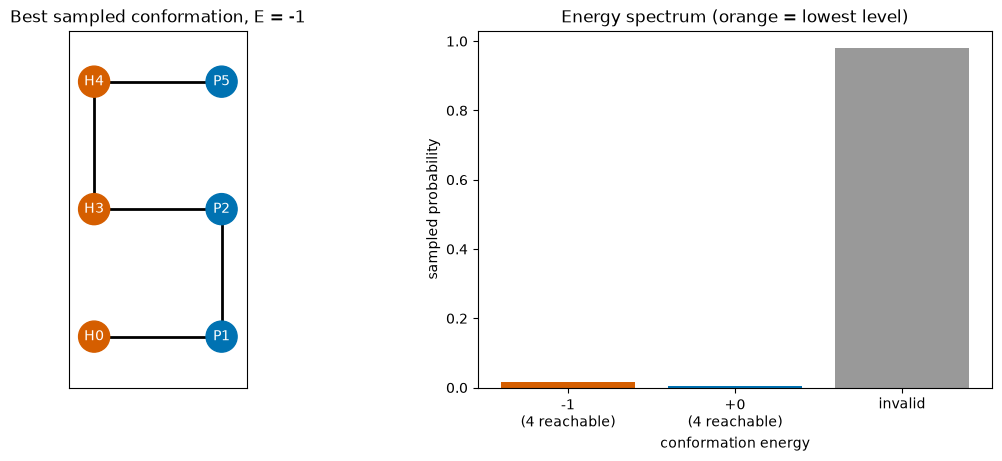

In [9]:
out = Path(tempfile.gettempdir()) / "folding_result.png"
analysis.analyze(data, out, top=10)
Image(out)

## Reading the results

- **Ranked list.** Rows are distinct valid conformations, sorted by energy and
  then probability. Each shows the bitstring that produced it and the bead
  coordinates in chain order. Several rows with the same energy are usually
  rotations, mirrors, or reversals of the same shape.
- **Best conformation.** Look for the H beads touching. Each contact between
  non-neighboring H beads is worth $-1$.
- **Spectrum.** The orange bar is the ground level. If it has visible height,
  QAOA is concentrating probability on the optimum. The gray bar is the fraction
  of samples that were not folds at all. A large gray bar is the cost of
  penalty-based encodings at small circuit depth.

## What to try next

1. Change `encoding` and compare qubit counts, circuit depth, and the fraction
   of valid samples.
2. Raise `reps` and `starts` and see how much the ground-level probability
   moves.
3. Try a longer sequence such as `"HPHPPHHPH"`. Watch the qubit count: it grows
   quickly, and the simulator limit appears around 22 qubits.
4. Set `backend_name` to a real device. Compare the invalid fraction against the
   simulator, which shows what hardware noise costs.
5. The same recipe (encode, build $H$, run QAOA, decode) solves other
   combinatorial problems. See the `optimization` scripts for the traveling
   salesman problem.